# EDA on Trading Data (BTCUSDT, synthetic)
Dataset: `trades_orderbook_STUDENT_dirty.csv`
Steps follow the instructor's PDF (EDA Steps for Trading Data).
Educational work, not financial advice. Data is synthetic.

## Step 1: Load and inspect

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/trades_orderbook_STUDENT_dirty.csv")
print(df.shape)       # rows, columns
print(df.head())      # first 5 rows

(2035, 18)
   trade_id                timestamp   symbol  side    price  quantity  \
0    100197               1790845352  BTCUSDT  sell  62004.9    0.0285   
1    101557  2026-10-01 09:21:03.172  BTCUSDT  sell  62180.8    0.3711   
2    100573  2026-10-01 09:07:37.614  BTCUSDT   buy  62090.2    0.0583   
3    101717  2026-10-01 09:23:29.337  BTCUSDT  sell  62237.0    0.0104   
4    100201  2026-10-01 09:02:35.129  BTCUSDT   buy  61994.8    0.1156   

   bid_price_1  bid_qty_1  bid_price_2  bid_qty_2  bid_price_3  bid_qty_3  \
0      62004.9      0.332      62004.8      0.280      62004.1      0.634   
1      62180.8      0.309      62180.6      0.260      62180.2      1.939   
2      62090.1      0.274      62089.8      0.310      62089.4      1.549   
3      62237.0      2.530      62236.8      4.173      62236.4      3.021   
4      61994.5      0.965      61994.3      0.809      61993.8      0.951   

   ask_price_1  ask_qty_1  ask_price_2  ask_qty_2  ask_price_3  ask_qty_3  
0    

In [2]:
print(df.dtypes)
print(df.columns.tolist())   # list the column names so we avoid typos later
df.info()

trade_id         int64
timestamp       object
symbol          object
side            object
price           object
quantity       float64
bid_price_1    float64
bid_qty_1      float64
bid_price_2    float64
bid_qty_2      float64
bid_price_3    float64
bid_qty_3      float64
ask_price_1    float64
ask_qty_1      float64
ask_price_2    float64
ask_qty_2      float64
ask_price_3    float64
ask_qty_3      float64
dtype: object
['trade_id', 'timestamp', 'symbol', 'side', 'price', 'quantity', 'bid_price_1', 'bid_qty_1', 'bid_price_2', 'bid_qty_2', 'bid_price_3', 'bid_qty_3', 'ask_price_1', 'ask_qty_1', 'ask_price_2', 'ask_qty_2', 'ask_price_3', 'ask_qty_3']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2035 entries, 0 to 2034
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   trade_id     2035 non-null   int64  
 1   timestamp    2035 non-null   object 
 2   symbol       2035 non-null   object 
 3   side         2020

Rows = 2035, columns = 18. `price` and `timestamp` are text (object), so they need converting.

## Step 2: Summarize

In [3]:
print(df["side"].value_counts(dropna=False))
print(df["symbol"].value_counts(dropna=False))

side
buy     970
sell    930
BUY      63
Sell     57
NaN      15
Name: count, dtype: int64
symbol
BTCUSDT     1974
btcusdt       24
BTC/USDT      21
BTC-USDT      16
Name: count, dtype: int64


In [4]:
# price is text, so make a temporary number version only for the summary
price_num = pd.to_numeric(df["price"].str.replace("$", "", regex=False).str.replace(",", "", regex=False))
print("price    min", price_num.min(), " max", price_num.max(), " mean", price_num.mean(), " median", price_num.median())
print("quantity min", df["quantity"].min(), " max", df["quantity"].max(), " mean", df["quantity"].mean(), " median", df["quantity"].median())
print(df.describe())

price    min -62183.7  max 6225050.0  mean 86215.81860696517  median 62116.350000000006
quantity min 0.0  max 2.7894  mean 0.08056769230769231  median 0.0488
            trade_id     quantity   bid_price_1    bid_qty_1   bid_price_2  \
count    2035.000000  2015.000000   2035.000000  2005.000000   2035.000000   
mean   101001.972973     0.080568  62108.614644     0.600706  62108.408157   
std       576.990768     0.111823     80.572214     0.827563     80.573348   
min    100001.000000     0.000000  61954.000000     0.014000  61953.700000   
25%    100503.500000     0.025950  62041.300000     0.180000  62041.100000   
50%    101001.000000     0.048800  62115.800000     0.346000  62115.500000   
75%    101500.500000     0.096050  62171.600000     0.701000  62171.400000   
max    102000.000000     2.789400  62253.900000    11.426000  62253.600000   

         bid_qty_2   bid_price_3    bid_qty_3   ask_price_1    ask_qty_1  \
count  2035.000000   2035.000000  2035.000000   2015.000000  20

Price max is in the millions but the median is about 62,000, so there are outliers. The min is negative, which is also wrong.

## Step 3: Find the problems

In [5]:
print("Missing values:")
print(df.isnull().sum())
print("Missing percentage:")
print(df.isnull().mean() * 100)

Missing values:
trade_id        0
timestamp       0
symbol          0
side           15
price          25
quantity       20
bid_price_1     0
bid_qty_1      30
bid_price_2     0
bid_qty_2       0
bid_price_3     0
bid_qty_3       0
ask_price_1    20
ask_qty_1       0
ask_price_2     0
ask_qty_2       0
ask_price_3     0
ask_qty_3       0
dtype: int64
Missing percentage:
trade_id       0.000000
timestamp      0.000000
symbol         0.000000
side           0.737101
price          1.228501
quantity       0.982801
bid_price_1    0.000000
bid_qty_1      1.474201
bid_price_2    0.000000
bid_qty_2      0.000000
bid_price_3    0.000000
bid_qty_3      0.000000
ask_price_1    0.982801
ask_qty_1      0.000000
ask_price_2    0.000000
ask_qty_2      0.000000
ask_price_3    0.000000
ask_qty_3      0.000000
dtype: float64


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate trade_id:", df["trade_id"].duplicated().sum())

print("Negative prices:", (price_num < 0).sum())
print("Zero quantity:", (df["quantity"] == 0).sum())
print("Crossed book (bid above ask):", (df["bid_price_1"] > df["ask_price_1"]).sum())
print("Price with $ or comma:", df["price"].str.contains(r"[$,]", na=False).sum())

Duplicate rows: 35
Duplicate trade_id: 35
Negative prices: 6
Zero quantity: 6
Crossed book (bid above ask): 10
Price with $ or comma: 50


In [7]:
# mixed timestamp formats
ts = df["timestamp"].astype(str)
print("Unix numbers:", ts.str.isdigit().sum())
print("DD/MM/YYYY  :", ts.str.contains("/").sum())
print("Standard    :", (~ts.str.isdigit() & ~ts.str.contains("/")).sum())

Unix numbers: 40
DD/MM/YYYY  : 78
Standard    : 1917


**Problems found**
- 35 duplicate rows (same trade_id)
- Missing values: price 25, quantity 20, side 15, bid_qty_1 30, ask_price_1 20
- `side` has BUY / Sell, and `symbol` has 4 different spellings
- price is text with `$` and `,` (50 rows)
- Negative prices (6) and huge prices (about 100 times too big)
- Zero quantity (6)
- Crossed book: bid above ask (10)
- 3 different timestamp formats, rows not in time order

## Step 4: Clean (reason written for each decision)

In [8]:
# 1. Drop duplicates by trade_id (same trade recorded twice)
df = df.drop_duplicates(subset="trade_id")
print(df.shape)

(2000, 18)


In [9]:
# 2. Standardize side and symbol (same meaning, different spelling)
df["side"] = df["side"].str.lower()
df["symbol"] = "BTCUSDT"
print(df["side"].value_counts(dropna=False))

side
buy     1012
sell     973
NaN       15
Name: count, dtype: int64


In [10]:
# 3. Convert price text to number (remove $ and commas)
df["price"] = df["price"].str.replace("$", "", regex=False).str.replace(",", "", regex=False)
df["price"] = pd.to_numeric(df["price"])
print(df["price"].dtype)

float64


In [11]:
# 4. Make all timestamps one format
ts = df["timestamp"].astype(str)
is_unix = ts.str.isdigit()
is_dmy = ts.str.contains("/")
is_std = ~is_unix & ~is_dmy

time = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
time[is_std] = pd.to_datetime(ts[is_std])
time[is_dmy] = pd.to_datetime(ts[is_dmy], format="%d/%m/%Y %H:%M:%S")
time[is_unix] = pd.to_datetime(ts[is_unix].astype("int64"), unit="s")   # 10 digits = seconds

df["timestamp"] = time
print(df["timestamp"].min(), "to", df["timestamp"].max())

2026-10-01 09:00:01.923000 to 2026-10-01 09:27:03.984000


All three formats land in the same half hour (09:00 to 09:27), so the conversion is correct.

In [12]:
# 5. Sort by time (rows were in random order)
df = df.sort_values("timestamp").reset_index(drop=True)

In [13]:
# 6. Fix the order book columns
spread_now = df["ask_price_1"] - df["bid_price_1"]
typical_spread = spread_now[spread_now > 0].median()      # about 0.1
print("typical spread:", typical_spread)

# missing ask = bid + typical spread (ask sits just above bid)
df["ask_price_1"] = df["ask_price_1"].fillna(df["bid_price_1"] + typical_spread)

# crossed book: a bid can never be above the ask, so the bid is wrong -> rebuild it
crossed = df["bid_price_1"] > df["ask_price_1"]
df.loc[crossed, "bid_price_1"] = df["ask_price_1"] - typical_spread
print("crossed rows fixed:", crossed.sum())

# missing bid quantity -> median
df["bid_qty_1"] = df["bid_qty_1"].fillna(df["bid_qty_1"].median())

typical spread: 0.10000000000582077
crossed rows fixed: 10


In [14]:
# 7. Zero or missing quantity -> median (a trade of 0 is not possible)
df.loc[df["quantity"] == 0, "quantity"] = np.nan
df["quantity"] = df["quantity"].fillna(df["quantity"].median())

## Step 5: Handle outliers (IQR method)

In [15]:
q1, q3 = df["price"].quantile([0.25, 0.75])
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print("normal price range:", low, "to", high)

outliers = (df["price"] < low) | (df["price"] > high)
print("outliers in price column:", outliers.sum())
print(df.loc[outliers, ["trade_id", "side", "price"]].head())

normal price range: 61844.09999999999 to 62368.500000000015
outliers in price column: 14
     trade_id  side      price
15     100016   buy   -61986.7
151    100152   buy  6200630.0
174    100175  sell   -61997.0
406    100407   buy  6199710.0
683    100684   NaN  6206410.0


Fix: a trade happens at the best price in the book, so a **buy = ask_price_1** and a **sell = bid_price_1**.
I replace outliers and missing prices with that value instead of deleting the rows.
First I use the same rule to fill the 15 missing `side` values (price equal to ask = buy, equal to bid = sell).

In [16]:
bad_price = outliers | df["price"].isnull()

# fill missing side using the good prices
no_side = df["side"].isnull() & ~bad_price
df.loc[no_side & (df["price"] == df["ask_price_1"]), "side"] = "buy"
df.loc[no_side & (df["price"] == df["bid_price_1"]), "side"] = "sell"

# replace bad prices with the book price
book_price = np.where(df["side"] == "buy", df["ask_price_1"], df["bid_price_1"])
df.loc[bad_price, "price"] = book_price[bad_price]

# any side still missing: price closer to the ask = buy, otherwise sell
mid = (df["ask_price_1"] + df["bid_price_1"]) / 2
df["side"] = df["side"].fillna(pd.Series(np.where(df["price"] >= mid, "buy", "sell"), index=df.index))

In [17]:
# check the cleaning worked
print("rows:", len(df))
print("missing values left:", df.isnull().sum().sum())
print("duplicates:", df["trade_id"].duplicated().sum())
print("price min/max:", df["price"].min(), df["price"].max())
print("quantity <= 0:", (df["quantity"] <= 0).sum())
print("crossed books:", (df["bid_price_1"] > df["ask_price_1"]).sum())

rows: 2000
missing values left: 0
duplicates: 0
price min/max: 61954.1 62253.9
quantity <= 0: 0
crossed books: 0


## Step 6: Engineer features

In [18]:
df["spread"] = df["ask_price_1"] - df["bid_price_1"]
df["mid_price"] = (df["ask_price_1"] + df["bid_price_1"]) / 2
df["order_imbalance"] = (df["bid_qty_1"] - df["ask_qty_1"]) / (df["bid_qty_1"] + df["ask_qty_1"])

df["return"] = df["mid_price"].pct_change()                 # change from the previous tick
df["volatility"] = df["return"].rolling(50).std()           # rolling volatility (last 50 ticks)
df["ma_50"] = df["mid_price"].rolling(50).mean()            # moving average

print(df[["timestamp", "price", "spread", "mid_price", "order_imbalance", "return", "volatility"]].tail())

                   timestamp    price  spread  mid_price  order_imbalance  \
1995 2026-10-01 09:27:01.231  62160.9     0.5   62161.15        -0.342398   
1996 2026-10-01 09:27:01.917  62161.9     0.1   62161.95        -0.666415   
1997 2026-10-01 09:27:02.976  62163.5     0.2   62163.40        -0.000830   
1998 2026-10-01 09:27:03.644  62158.0     0.1   62157.95         0.959648   
1999 2026-10-01 09:27:03.984  62151.7     0.1   62151.75        -0.711957   

            return  volatility  
1995  2.220446e-16    0.000056  
1996  1.286977e-05    0.000054  
1997  2.332617e-05    0.000054  
1998 -8.767217e-05    0.000055  
1999 -9.974589e-05    0.000055  


Every feature only uses the current and earlier rows, so there is no look-ahead bias.

## Step 7: Resample into 1-minute OHLCV candles

In [19]:
candles = df.set_index("timestamp").resample("1min").agg(
    open=("price", "first"),
    high=("price", "max"),
    low=("price", "min"),
    close=("price", "last"),
    volume=("quantity", "sum"),
)
candles = candles.sort_index()
print(candles.head())
print("number of candles:", len(candles))

                        open     high      low    close  volume
timestamp                                                      
2026-10-01 09:00:00  61994.6  62006.7  61962.9  61972.0  6.9088
2026-10-01 09:01:00  61969.0  62030.4  61967.2  62011.2  7.5618
2026-10-01 09:02:00  62019.6  62020.4  61976.7  61977.9  7.1423
2026-10-01 09:03:00  61978.9  62039.0  61954.1  62032.7  5.9706
2026-10-01 09:04:00  62028.7  62062.9  62020.1  62026.1  4.3097
number of candles: 28


## Step 8: Visualize

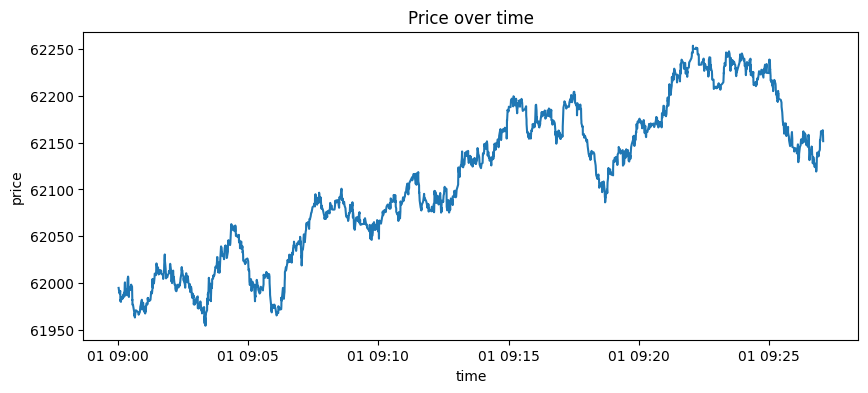

In [20]:
# price line chart
plt.figure(figsize=(10, 4))
plt.plot(df["timestamp"], df["price"])
plt.title("Price over time")
plt.xlabel("time")
plt.ylabel("price")
plt.show()

Price stays in a narrow band, between about 61,950 and 62,250 USDT, over the 27 minutes. It moves up and down in small waves with no sudden jumps, which confirms the outliers were removed.

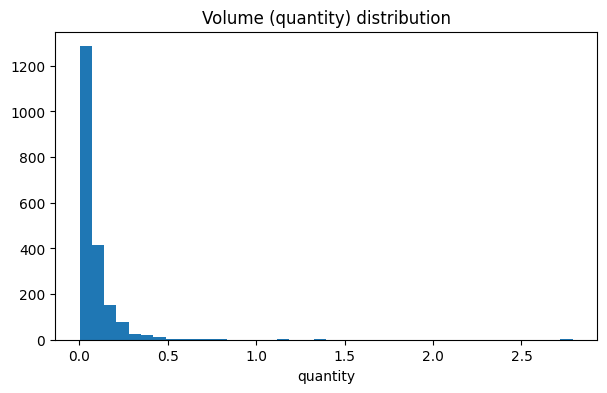

In [21]:
# volume histogram
plt.figure(figsize=(7, 4))
plt.hist(df["quantity"], bins=40)
plt.title("Volume (quantity) distribution")
plt.xlabel("quantity")
plt.show()

Most trades are very small. The median is about 0.05 BTC, and three quarters of trades are below 0.1. A few large trades (up to about 2.8 BTC) create a long tail on the right, so the distribution is right-skewed.

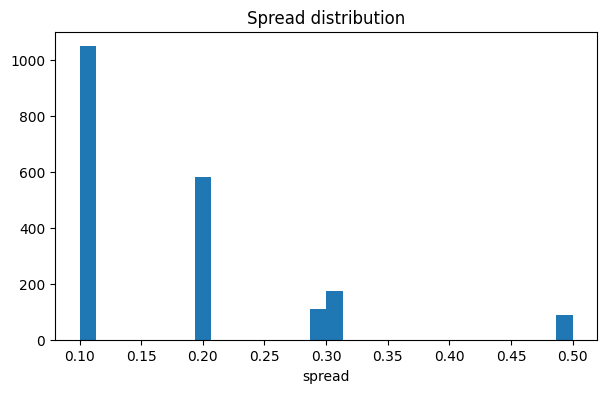

In [22]:
# spread distribution
plt.figure(figsize=(7, 4))
plt.hist(df["spread"], bins=30)
plt.title("Spread distribution")
plt.xlabel("spread")
plt.show()

The spread is mostly 0.1, with 0.2 the next most common, and it never goes above 0.5. This means the order book is tight, so buying and selling costs very little.

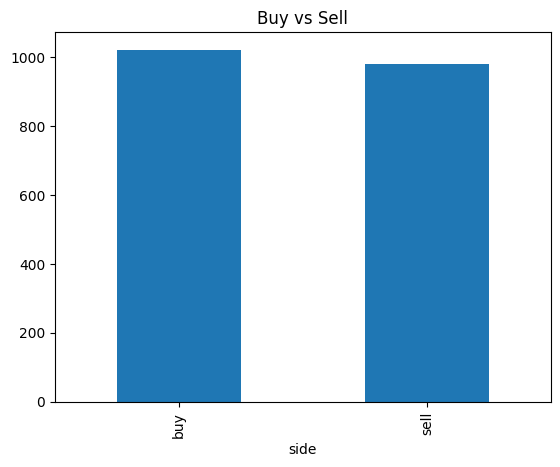

In [23]:
# buy vs sell counts
df["side"].value_counts().plot(kind="bar")
plt.title("Buy vs Sell")
plt.show()

There are 1,021 buys and 979 sells, so the split is almost even. There is no strong buying or selling pressure in this data.

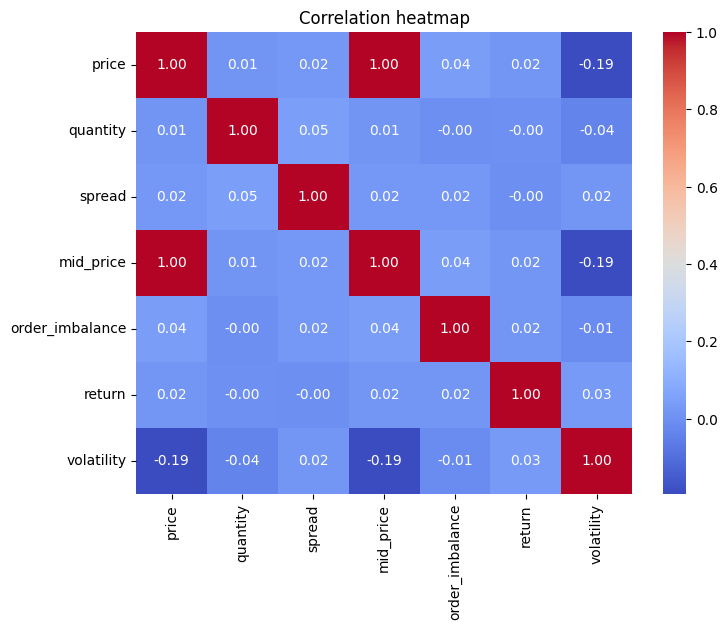

In [24]:
# correlation heatmap
cols = ["price", "quantity", "spread", "mid_price", "order_imbalance", "return", "volatility"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

Price and mid_price have a correlation of 1.0 because they are almost the same number. Every other pair is close to zero. For example, order_imbalance has only 0.04 correlation with price, so imbalance alone does not predict price. The only noticeable value is volatility vs price (-0.19), which is still weak.

## Compare groups and conditions

In [25]:
# compare buy and sell (one column with another)
print(df.groupby("side")[["price", "quantity", "spread"]].mean())

             price  quantity    spread
side                                  
buy   62104.934672  0.077922  0.172086
sell  62112.223289  0.083466  0.177835


Buys and sells have almost the same average price, quantity and spread, so the two groups behave alike.

In [26]:
# condition: rows where order imbalance is above 0.3
strong = df[df["order_imbalance"] > 0.3]
print("rows with imbalance > 0.3:", len(strong), "out of", len(df))
print(strong["side"].value_counts())

rows with imbalance > 0.3: 613 out of 2000
side
buy     319
sell    294
Name: count, dtype: int64


## Step 9: Prepare for a model

In [27]:
# 1-minute features
candles["return"] = candles["close"].pct_change()
candles["ma_3"] = candles["close"].rolling(3).mean()
candles["imbalance"] = df.set_index("timestamp")["order_imbalance"].resample("1min").mean()

# target: is the price higher 5 minutes later? (1 = up, 0 = down)
candles["future_close"] = candles["close"].shift(-5)
candles["target"] = (candles["future_close"] > candles["close"]).astype(int)

data = candles.dropna()          # removes rows without a future price or without enough history
print(data.shape)

(21, 10)


In [28]:
# split by time (never shuffle): first 70% train, last 30% test
features = ["return", "ma_3", "imbalance", "volume"]
cut = int(len(data) * 0.7)
train = data.iloc[:cut].copy()
test = data.iloc[cut:].copy()
print("train:", train.index.min(), "to", train.index.max())
print("test :", test.index.min(), "to", test.index.max())

# scale using the train mean and std only
mean = train[features].mean()
std = train[features].std()
train[features] = (train[features] - mean) / std
test[features] = (test[features] - mean) / std

train: 2026-10-01 09:02:00 to 2026-10-01 09:15:00
test : 2026-10-01 09:16:00 to 2026-10-01 09:22:00


In [29]:
# simple rule: buy when order imbalance is above 0.3
rule = (data.loc[test.index, "imbalance"] > 0.3).astype(int)
print("rule accuracy on test:", (rule == test["target"]).mean())

rule accuracy on test: 0.42857142857142855


The data covers only about 27 minutes, so there are very few candles. This result is just for practice.

## Save the cleaned file

In [30]:
df.to_csv("../data/trades_clean.csv", index=False)
candles.to_csv("../data/candles_1min.csv")
print("saved")

saved


## Check against the answer key (optional)

In [31]:
from pathlib import Path

key_file = Path("../data/trades_orderbook_clean_ANSWER_KEY.csv")
if key_file.exists():
    key = pd.read_csv(key_file).set_index("trade_id").sort_index()
    mine = df.set_index("trade_id").sort_index()
    print("same row count:", len(key) == len(mine))
    for col in ["price", "ask_price_1", "bid_price_1"]:
        print(col, "matches:", np.allclose(key[col], mine[col]))
    print("side differences:", (key["side"] != mine["side"]).sum())
else:
    print("answer key not found in data folder")

answer key not found in data folder


## Business insight
- The raw file had many problems (duplicates, missing values, wrong prices, mixed formats); after cleaning, 2,000 valid trades remain.
- Prices stay in a narrow band (about 61,950 to 62,250) and the spread is usually 0.1 to 0.2, so this market is tight.
- Buy and sell counts are close to equal, so there is no strong one-sided pressure.
- About 30% of ticks have order imbalance above 0.3, and those are split almost evenly between buys and sells. So imbalance alone does not separate buyers from sellers.
- The simple rule scored below 50% on a tiny test set (only a few candles), so it shows no edge here. A real strategy needs more data, a backtest and paper trading before any signal goes to 3Commas.